In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helper_functions import get_training_data, SLML, ReconstructPeak, get_backtransformed_Ft, Ftilde_contour
import time

## Generating the lens and its images

In [2]:
## these are the lens parameters that you can play around with
k = 0.25
phi_g = np.pi / 3
y0 = 0.3018
y1 = y0 # use y0-0.05 for four image case and y0+0.05 for two image case

######
g1 = -k*np.cos(2*phi_g)
g2 = -k*np.sin(2*phi_g)
## lens object
lens = SLML(k=k, g1=g1, g2=g2, mratio=1, y1=y1, y2=0)

### Getting the images and their properties

In [3]:
print("Images are located at [x1, x2]:\n", lens.img)
print("\nMagnifications of the images:\n", lens.img_mag)
print("\nImage time delays:\n", lens.img_td)

Images are located at [x1, x2]:
 [[ 1.57595572 -0.6438379 ]
 [-0.75087917 -0.53229997]]

Magnifications of the images:
 [ 1.82766464 -0.78248829]

Image time delays:
 [0.         0.96608926]


### Plotting the inverse magnification map and check image locations

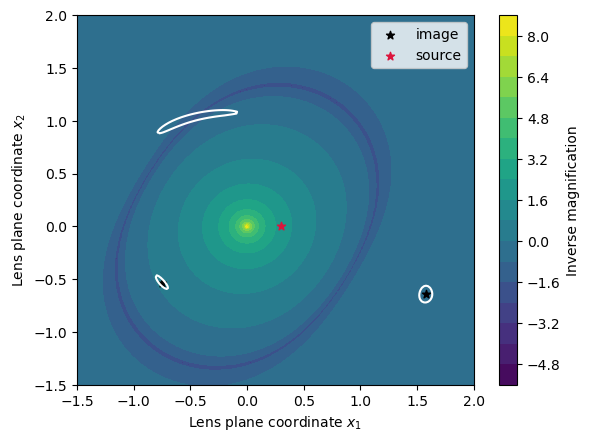

In [4]:
x_ = np.linspace(-1.5, 2, 200)
X1, X2 = np.meshgrid(x_, x_)
mag_map = np.abs(lens.magnification(X1, X2))
gtd_map = np.linalg.norm(lens.grad_time_delay(X1, X2), axis=-1)

cont = plt.contourf(X1, X2, np.log10(1./mag_map), levels=20)
cbar = plt.colorbar(cont)
plt.contour(X1, X2, gtd_map, levels=[5e-2], colors='w')

for img in lens.img:
    plt.scatter(*img.T, c='k', marker='*')
plt.scatter(lens.y1, lens.y2, c='crimson', marker='*')
plt.scatter([],[], c='k', marker='*', label='image')
plt.scatter([],[], c='crimson', marker='*', label='source')

cbar.set_label('Inverse magnification')
plt.xlabel(r'Lens plane coordinate $x_1$')
plt.ylabel(r'Lens plane coordinate $x_2$')
plt.legend()
plt.show()

## Generating $\widetilde{F}(t)$ and its transformation

This is the currently employed transformation, which as we discussed is not the optimal one especially near the caustic crossing regions where the image numbers change between 2 and 4.

In [5]:
num = int(2**np.ceil(np.log2(2e5/np.pi)))
t_dense = np.linspace(0, 200, num)

In [6]:
tStart = time.perf_counter()
lens, Ft_vals, Ft_transf = get_training_data(t_dense, y1=y1, k=k, phi_g=phi_g, y2=0)
tEnd = time.perf_counter()
print("Time taken for Ft computation:", tEnd-tStart) #~6 seconds

Time taken for Ft computation: 6.160969654003566


In [7]:
## peak reconstructed Ft
Ft_recons = ReconstructPeak(lens, t_dense, Ft_vals).get_peak_reconstructed_Ft()
## back transformed Ft + reconstruction
Ft_bt = get_backtransformed_Ft(lens, Ft_transf, t_dense) 
Ft_bt_recons = ReconstructPeak(lens, t_dense, Ft_bt).get_peak_reconstructed_Ft()

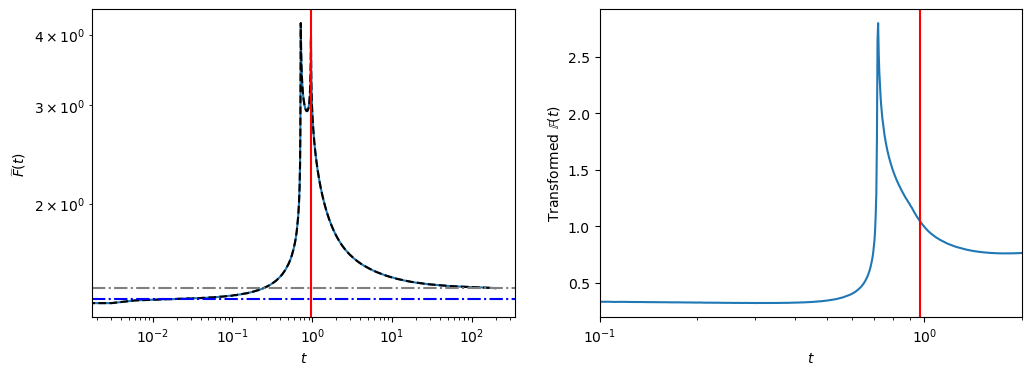

In [8]:
%matplotlib inline
plt.figure(figsize=(12, 4))

plt.subplot(121)
plt.plot(t_dense, Ft_vals)
plt.plot(t_dense, Ft_bt_recons, c='k', ls='--')
for img_td in lens.img_td:
    plt.axvline(img_td, c='r')
plt.xscale('log')
plt.yscale('log')
plt.axhline(lens.img_macro_mag**0.5, c='grey', ls='-.')
plt.axhline(np.abs(lens.img_mag[0])**0.5, c='blue', ls='-.')
# plt.xlim(1e-1, 2)
plt.xlabel(r'$t$')
plt.ylabel(r'$\widetilde{F}(t)$')

plt.subplot(122)
plt.plot(t_dense, Ft_transf)
for img_td in lens.img_td:
    plt.axvline(img_td, c='r')
plt.xscale('log')
plt.xlim(1e-1, 2)
plt.xlabel(r'$t$')
plt.ylabel(r'Transformed $\mathbb{F}(t)$')
plt.show()